Initial Dataset Head:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

Dataset Shape: (150, 4)

Missing Values Count:
 sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64

Mean of standardized features (approx 0): [-0. -0. -0. -0.]
Std of standardized features (approx 1): [1. 1. 1. 1.]

Covariance Matrix (4x4):
[[ 1.0067 -0.1184  0.8776  0.8234]
 [-0.1184  1.0067 -0.4313 -0.3686]
 [ 0.8776 -0.4313  1.0067  0.9693]
 [ 0.8234 -0.3686  0.9693  1.0067]]

Eigenvalues (descending order):
[2.93808505 0.9201649  0.14774182 0.02085386]

Eigen

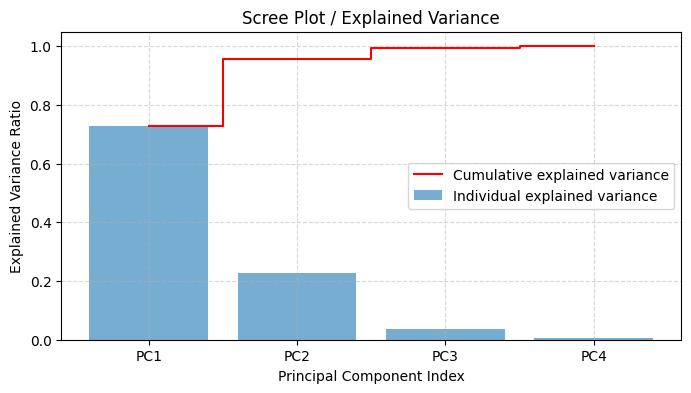


Projected Data Head (2D):
        PC1       PC2  Target
0  2.264703  0.480027  setosa
1  2.080961 -0.674134  setosa
2  2.364229 -0.341908  setosa
3  2.299384 -0.597395  setosa
4  2.389842  0.646835  setosa


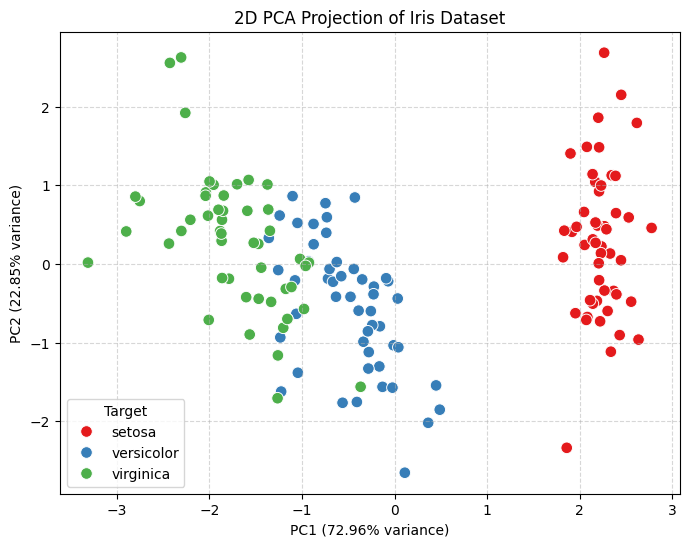


Comparison for First Sample:
Original Sample:      [5.1 3.5 1.4 0.2]
Reconstructed Sample: [5.019 3.515 1.466 0.252]

Mean Squared Reconstruction Error (using top 2 components): 0.0355
Mean Squared Reconstruction Error (using all 4 components): 5.7366648091e-31


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler, MinMaxScaler

iris = load_iris()
feature_names = iris.feature_names
X = iris.data
y = iris.target

df = pd.DataFrame(X, columns=feature_names)
print("Initial Dataset Head:")
print(df.head())
print("\nDataset Shape:", df.shape)

print("\nMissing Values Count:\n", df.isnull().sum())

min_max_scaler = MinMaxScaler()
X_normalized = min_max_scaler.fit_transform(X)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("\nMean of standardized features (approx 0):", np.round(X_scaled.mean(axis=0), 2))
print("Std of standardized features (approx 1):", np.round(X_scaled.std(axis=0), 2))

cov_matrix = np.cov(X_scaled, rowvar=False)

print("\nCovariance Matrix (4x4):")
print(np.round(cov_matrix, 4))

eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)

sorted_indices = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[sorted_indices]
eigenvectors = eigenvectors[:, sorted_indices]

print("\nEigenvalues (descending order):")
print(eigenvalues)

print("\nEigenvectors (Principal Components as columns):")
print(eigenvectors)

total_variance = np.sum(eigenvalues)
explained_variance_ratio = eigenvalues / total_variance
cumulative_variance_ratio = np.cumsum(explained_variance_ratio)

variance_df = pd.DataFrame({
    'Principal Component': [f'PC{i+1}' for i in range(len(eigenvalues))],
    'Eigenvalue': eigenvalues,
    'Explained Variance Ratio': explained_variance_ratio,
    'Cumulative Variance Ratio': cumulative_variance_ratio
})
print("\nVariance Analysis Table:")
print(variance_df)

plt.figure(figsize=(8, 4))
plt.bar(range(1, 5), explained_variance_ratio, alpha=0.6, align='center', label='Individual explained variance')
plt.step(range(1, 5), cumulative_variance_ratio, where='mid', color='red', label='Cumulative explained variance')
plt.ylabel('Explained Variance Ratio')
plt.xlabel('Principal Component Index')
plt.xticks(range(1, 5), [f'PC{i}' for i in range(1, 5)])
plt.title('Scree Plot / Explained Variance')
plt.legend(loc='best')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

k = 2
projection_matrix = eigenvectors[:, :k]

X_pca = np.dot(X_scaled, projection_matrix)

pca_df = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
pca_df['Target'] = [iris.target_names[target] for target in y]

print("\nProjected Data Head (2D):")
print(pca_df.head())

plt.figure(figsize=(8, 6))
sns.scatterplot(x='PC1', y='PC2', hue='Target', data=pca_df, palette='Set1', s=70)
plt.title('2D PCA Projection of Iris Dataset')
plt.xlabel(f'PC1 ({explained_variance_ratio[0]*100:.2f}% variance)')
plt.ylabel(f'PC2 ({explained_variance_ratio[1]*100:.2f}% variance)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

X_reconstructed_scaled = np.dot(X_pca, projection_matrix.T)

X_reconstructed = scaler.inverse_transform(X_reconstructed_scaled)

reconstruction_error = np.mean((X - X_reconstructed) ** 2)

print("\nComparison for First Sample:")
print("Original Sample:     ", np.round(X[0], 3))
print("Reconstructed Sample:", np.round(X_reconstructed[0], 3))
print(f"\nMean Squared Reconstruction Error (using top 2 components): {reconstruction_error:.4f}")

X_pca_full = np.dot(X_scaled, eigenvectors)
X_reconstructed_full = scaler.inverse_transform(np.dot(X_pca_full, eigenvectors.T))
full_reconstruction_error = np.mean((X - X_reconstructed_full) ** 2)
print(f"Mean Squared Reconstruction Error (using all 4 components): {full_reconstruction_error:.10e}")